#0. Setup

In [ ]:
!pip install -q ultralytics
!pip install roboflow

In [ ]:
import tensorflow as tf
import numpy as np
import cv2
import matplotlib.pyplot as plt
import os
import zipfile
import shutil
import requests
import torch
import sys
import ultralytics
import roboflow
import random
import glob
import pathlib
import yaml
import hashlib
import re

from collections import Counter, defaultdict
from PIL import Image
from roboflow import Roboflow
from ultralytics import YOLO
from google.colab import userdata
from pathlib import Path

#1. Datasets
Facemask: https://universe.roboflow.com/ds/FougzrDchS?key=rRR8ymL2Z7
  ```
  - take /train/
  ```
Glasses: https://universe.roboflow.com/pex-5-ylpua/pex5-gxq3t
  ```
  - take /train/
  ```
Hat: https://universe.roboflow.com/ds/NkHS08rp5A?key=5lrmvHB2LG
  ```
  - take half of /train/
  ```

##Download datasets

In [ ]:
rf = Roboflow(api_key=userdata.get('roboflow_api_key'))

# Facemask
project = rf.workspace("yolov11-axnhn").project("yolo-7woqc")
version = project.version(2)
facemask_dataset = version.download(
    model_format="yolov11",
    location='/content/datasets/facemask'
  )

# Glasses
project = rf.workspace("pex-5-ylpua").project("pex5-gxq3t")
version = project.version(4)
glasses_dataset = version.download(
    model_format="yolov11",
    location='/content/datasets/glasses'
  )

# Hats
project = rf.workspace("object-detection-cwcjo").project("caps-gi4un")
version = project.version(2)
hats_dataset = version.download(
    model_format="yolov11",
    location='/content/datasets/hats'
  )

print('\n')
print('Facemask dataset:', facemask_dataset.location)
print('Glasses dataset:', glasses_dataset.location)
print('Hats dataset:', hats_dataset.location)

loading Roboflow workspace...
loading Roboflow project...
loading Roboflow workspace...
loading Roboflow project...
loading Roboflow workspace...
loading Roboflow project...


Facemask dataset: /content/datasets/facemask
Glasses dataset: /content/datasets/glasses
Hats dataset: /content/datasets/hats


##Dataset preparation

The train set for `Hat` has about 2,000 images, so we only take about half of them.

In [ ]:
hats_train_images_dir = '/content/datasets/hats/train/images'
hats_train_labels_dir = '/content/datasets/hats/train/labels'

image_extensions = ('*.jpg', '*.jpeg', '*.png', '*.JPG', '*.JPEG', '*.PNG')
images = []
for ext in image_extensions:
    images.extend(glob.glob(os.path.join(hats_train_images_dir, ext)))

print(f"images: {len(images)}")

num_to_delete = len(images) // 2

images_to_delete = random.sample(images, num_to_delete)

# Delete selected images and their corresponding labels
deleted_count = 0
for img_path in images_to_delete:
    # Get base filename without extension
    base_name = os.path.splitext(os.path.basename(img_path))[0]

    # Corresponding label file (assuming .txt for YOLO)
    label_path = os.path.join(hats_train_labels_dir, f"{base_name}.txt")

    # Delete image
    if os.path.exists(img_path):
        os.remove(img_path)

    # Delete label
    if os.path.exists(label_path):
        os.remove(label_path)

    deleted_count += 1


images_in_dir = os.listdir('/content/datasets/hats/train/images')
labels_in_dir = os.listdir('/content/datasets/hats/train/labels')

print(f"images after deletion: {len(images_in_dir)}")
print(f"labels after deletion: {len(labels_in_dir)}")

images: 1021
images after deletion: 511
labels after deletion: 511


The combined dataset must satisfy following requirements:
  ```
  - 3 classes: Facemask, Glasses, Hat
  - YOLO format
  - 80/10/10
  ```

In [ ]:
datasets_root = '/content/datasets'
sub_datasets = ['facemask', 'glasses', 'hats']

# Setup combined dataset directory structure
comb_dir = os.path.join(datasets_root, 'accessories')
for split in ['train', 'valid', 'test']:
    os.makedirs(os.path.join(comb_dir, split, 'images'), exist_ok=True)
    os.makedirs(os.path.join(comb_dir, split, 'labels'), exist_ok=True)

# Class mapping for YOLO formatting to prevent conflict
# Let's map: Facemask -> 0, Glasses -> 1, Hat -> 2
# Since original datasets might have single class labeled as 0
class_map = {
    'facemask': 0,
    'glasses': 1,
    'hats': 2
}

# Collect all training samples
all_samples = []

for ds in sub_datasets:
    img_dir = os.path.join(datasets_root, ds, 'train', 'images')
    lbl_dir = os.path.join(datasets_root, ds, 'train', 'labels')

    if not os.path.exists(img_dir):
        continue

    for img_name in os.listdir(img_dir):
        base, ext = os.path.splitext(img_name)
        if ext.lower() in ['.jpg', '.jpeg', '.png']:
            img_path = os.path.join(img_dir, img_name)
            lbl_path = os.path.join(lbl_dir, f"{base}.txt")
            if os.path.exists(lbl_path):
                all_samples.append((img_path, lbl_path, ds))

# 3. Shuffle and split into 90/10/10
random.seed(67)
random.shuffle(all_samples)

total = len(all_samples)
n_val = int(total * 0.1)
n_test = int(total * 0.1)
n_train = total - n_val - n_test

splits = {
    'train': all_samples[:n_train],
    'valid': all_samples[n_train:n_train+n_val],
    'test': all_samples[n_train+n_val:]
}

print(f"Total items collected: {total}. Splits - Train: {n_train}, Valid: {n_val}, Test: {n_test}")

# 4. Copy and update label files to use corrected class IDs
for split, samples in splits.items():
    for img_path, lbl_path, source_ds in samples:
        img_name = os.path.basename(img_path)
        lbl_name = os.path.basename(lbl_path)

        dest_img_path = os.path.join(comb_dir, split, 'images', f"{source_ds}_{img_name}")
        dest_lbl_path = os.path.join(comb_dir, split, 'labels', f"{source_ds}_{lbl_name}")

        # Copy image file
        shutil.copy2(img_path, dest_img_path)

        # Copy and remap label annotations to correct index
        target_class_id = class_map[source_ds]
        with open(lbl_path, 'r') as f_in, open(dest_lbl_path, 'w') as f_out:
            for line in f_in:
                parts = line.strip().split()
                if len(parts) > 0:
                    parts[0] = str(target_class_id)
                    f_out.write(' '.join(parts) + '\n')

print("\nAccessories dataset creation and division successfully completed!")

Total items collected: 1940. Splits - Train: 1552, Valid: 194, Test: 194

Accessories dataset creation and division successfully completed!


In [ ]:
DATA_ROOT = Path("/content/datasets/accessories")
# USE_DRIVE = True

# if USE_DRIVE:
#     from google.colab import drive
#     drive.mount("/content/drive")
#     RUNS_DIR = "/content/drive/MyDrive/accessories_runs"
# else:
RUNS_DIR = "/content/runs"

assert DATA_ROOT.exists(), f"{DATA_ROOT} not found"
for s in ("train", "valid", "test"):
    assert (DATA_ROOT / s / "images").is_dir() and (DATA_ROOT / s / "labels").is_dir(), f"missing {s}/images or {s}/labels"
print("Dataset folders found.")

Dataset folders found.


In [ ]:
# Configure paths and classes with relative path format
data_yaml_content = {
    'path': '../accessories',  # relative path reference
    'train': 'train/images',
    'val': 'valid/images',
    'test': 'test/images',
    'nc': 3,
    'names': ['facemask', 'glasses', 'hat']
}

# Write the data.yaml inside the accessories dataset directory
yaml_path = '/content/datasets/accessories/data.yaml'
with open(yaml_path, 'w') as file:
    yaml.dump(data_yaml_content, file, default_flow_style=False)

print(f"Successfully created data.yaml at {yaml_path}:")
with open(yaml_path, 'r') as file:
    print(file.read())

Successfully created data.yaml at /content/datasets/accessories/data.yaml:
names:
- facemask
- glasses
- hat
nc: 3
path: ../accessories
test: test/images
train: train/images
val: valid/images



In [ ]:
cfg = yaml.safe_load(open(DATA_ROOT / "data.yaml"))
names = cfg["names"]
names = dict(enumerate(names)) if isinstance(names, list) else {int(k): v for k, v in names.items()}
print("Classes in data.yaml:", names)
assert len(names) == 3, "expected exactly 3 classes"

EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
RF = re.compile(r"^(.*?)_(?:jpg|jpeg|png|bmp|webp)\.rf\.[0-9a-fA-F]+$", re.I)   # Roboflow augmented-copy naming
group_splits, hash_splits = defaultdict(set), defaultdict(set)

for split in ("train", "valid", "test"):
    imgs = [p for p in (DATA_ROOT / split / "images").iterdir() if p.suffix.lower() in EXTS]
    inst, empty, bad = Counter(), 0, 0
    for p in imgs:
        m = RF.match(p.stem)
        group_splits[m.group(1) if m else p.stem].add(split)
        hash_splits[hashlib.md5(p.read_bytes()).hexdigest()].add(split)
        lp = DATA_ROOT / split / "labels" / f"{p.stem}.txt"
        lines = [l.split() for l in lp.read_text().splitlines() if l.strip()] if lp.exists() else []
        if not lines:
            empty += 1
        for parts in lines:
            try:
                ok = len(parts) == 5 and int(float(parts[0])) in names
            except ValueError:
                ok = False
            if ok:
                inst[names[int(float(parts[0]))]] += 1
            else:
                bad += 1
    print(f"{split:6s} images={len(imgs):6d}  empty/missing label files={empty:5d}  bad label lines={bad}")
    print("       instances per class:", dict(inst))

leaked_groups = [g for g, s in group_splits.items() if len(s) > 1]
leaked_hashes = [h for h, s in hash_splits.items() if len(s) > 1]
print(f"\nSource images found in more than one split: {len(leaked_groups)}  (should be 0)")
print(f"Identical files found in more than one split: {len(leaked_hashes)}  (should be 0)")

Classes in data.yaml: {0: 'facemask', 1: 'glasses', 2: 'hat'}
train  images=  2266  empty/missing label files=    0  bad label lines=56
       instances per class: {'glasses': 1327, 'hat': 1241, 'facemask': 2534}
valid  images=   417  empty/missing label files=    0  bad label lines=2
       instances per class: {'facemask': 600, 'hat': 167, 'glasses': 284}
test   images=   421  empty/missing label files=    0  bad label lines=7
       instances per class: {'facemask': 434, 'glasses': 270, 'hat': 181}

Source images found in more than one split: 616  (should be 0)
Identical files found in more than one split: 654  (should be 0)


In [ ]:
DATA_YAML = "/content/datasets/accessories/data.yaml"
cfg["path"] = str(DATA_ROOT)
cfg["train"], cfg["val"], cfg["test"] = "train/images", "valid/images", "test/images"
cfg["names"] = names
cfg["nc"] = len(names)
cfg.pop("roboflow", None)
with open(DATA_YAML, "w") as f:
    yaml.safe_dump(cfg, f, sort_keys=False)
print(open(DATA_YAML).read())

names:
  0: facemask
  1: glasses
  2: hat
nc: 3
path: /content/datasets/accessories
test: test/images
train: train/images
val: valid/images



In [ ]:
def display_dir_tree(startpath, max_depth=3):
    for root, dirs, files in os.walk(startpath):
        level = root.replace(startpath, '').count(os.sep)
        if level >= max_depth:
            continue
        indent = ' ' * 4 * level
        print(f"{indent}📁 {os.path.basename(root)}/")
        subindent = ' ' * 4 * (level + 1)
        # Display first few files to avoid cluttering
        for f in files[:5]:
            print(f"{subindent}📄 {f}")
        if len(files) > 5:
            print(f"{subindent}📄 ... and {len(files) - 5} more files")

display_dir_tree('/content/datasets')

📁 datasets/
    📁 hats/
        📄 README.roboflow.txt
        📄 data.yaml
        📄 README.dataset.txt
        📁 test/
        📁 train/
        📁 valid/
    📁 glasses/
        📄 README.roboflow.txt
        📄 data.yaml
        📄 README.dataset.txt
        📁 test/
        📁 train/
        📁 valid/
    📁 accessories/
        📄 data.yaml
        📁 test/
        📁 train/
            📄 labels.cache
        📁 valid/
            📄 labels.cache
    📁 facemask/
        📄 README.roboflow.txt
        📄 data.yaml
        📄 README.dataset.txt
        📁 test/
        📁 train/
        📁 valid/


#2. Pretrained YOLO11n

In [ ]:
os.environ['PYDEVD_DISABLE_FILE_VALIDATION'] = '1'

In [ ]:
model = YOLO('yolo11n.pt')
model.info()

YOLO11n summary: 181 layers, 2,624,080 parameters, 0 gradients, 6.7 GFLOPs


(181, 2624080, 0, 6.6733184)

#3. Fine-tuning

In [ ]:
IMG_SIZE = 640
BATCH = 8
EPOCHS = 30
WORKERS = 0
DATA_YAML = '/content/datasets/accessories/data.yaml'
RUN_DIR = '/content/runs/'

In [ ]:
# !yolo detect train model=yolo11n.pt data=/content/datasets/accessories/data.yaml epochs=1 fraction=0.1 batch=8 workers=0 imgsz=640 verbose=False project=/content/runs name=memtest

Ultralytics 8.4.197 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/accessories/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=0.1, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=memtest, nbs=64, nms=None, opset=None, optimize=Fals

In [ ]:
!yolo detect train model=yolo11n.pt data=/content/datasets/accessories/data.yaml epochs=30 batch=16 workers=2 imgsz=640 seed=0 project={RUNS_DIR} name=yolo11n_accessories

Ultralytics 8.4.197 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/accessories/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11n_accessories-2, nbs=64, nms=None, opset=Non

#Demo


Using model weights from: /content/runs/yolo11n_accessories-2/weights/best.pt

image 1/1 /content/images (1).jpg: 480x640 3 facemasks, 8.3ms
Speed: 1.9ms preprocess, 8.3ms inference, 1.4ms postprocess per image at shape (1, 3, 480, 640)


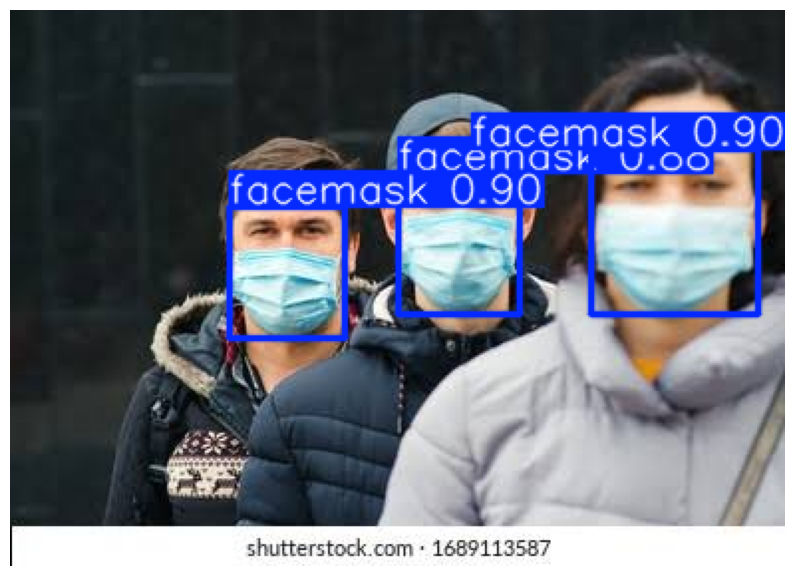

In [ ]:
import cv2
import glob
import os
import matplotlib.pyplot as plt
from ultralytics import YOLO

# 1. Automatically find the best.pt weights from the accessories runs
weights_path = '/content/runs/yolo11n_accessories/weights/best.pt'
if not os.path.exists(weights_path):
    # Fallback to check other generated run directories (e.g., yolo11n_accessories-2)
    paths = sorted(glob.glob('/content/runs/yolo11n_accessories*/weights/best.pt'))
    if paths:
        weights_path = paths[-1]

print(f"Using model weights from: {weights_path}")

# 2. Load the model
model = YOLO(weights_path)

# 3. Perform object detection on images.jpg
image_path = '/content/images (1).jpg'
results = model(image_path)

# 4. Save and plot results
for result in results:
    # Plot predictions to a numpy array
    annotated_img = result.plot()

    # Convert BGR to RGB for matplotlib
    annotated_img_rgb = cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB)

    # Display
    plt.figure(figsize=(10, 8))
    plt.imshow(annotated_img_rgb)
    plt.axis('off')
    plt.show()